# ML Assignment 2: Hotel Booking Cancellation Prediction
**Course:** Machine Learning (M.Tech AIML)  
**Dataset:** Hotel Booking Demand (Kaggle)  
**Target:** `is_canceled` (1 = cancelled, 0 = not cancelled)  
**Models:** Logistic Regression, Decision Tree, kNN, Gaussian Naive Bayes, Random Forest  
**Metrics:** Accuracy, AUC, Precision, Recall, F1, MCC

Imports and settings

In [1]:
import os, time, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Setup done")

Setup done


Load the dataset

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# If the file is directly in My Drive:
file_path = "/content/drive/MyDrive/hotel_bookings.csv"

# If it is inside a folder, use this instead (change the folder name):
# file_path = "/content/drive/MyDrive/ML_Assignment_2/hotel_bookings.csv"

raw_df = pd.read_csv(file_path)
print("Shape:", raw_df.shape)
raw_df.head()

Mounted at /content/drive
Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


STEP 1: Dataset choice and understanding

## Step 1: Dataset Choice
**Why this dataset?**  
- Real-world business problem: predicting booking cancellations helps hotels with overbooking and revenue management.  
- Meets all constraints: 30+ features (min 12), 100k+ rows (min 1,000), genuine missing values, mixed numeric and categorical features, and a binary target with class imbalance.  

**Target variable:** `is_canceled`

Structure, types, and constraint check

In [3]:
print("Rows:", raw_df.shape[0], "| Columns:", raw_df.shape[1])
print("Features (excluding target):", raw_df.shape[1] - 1)
print("Meets min 12 features? ", raw_df.shape[1] - 1 >= 12)
print("Meets min 1000 rows?   ", raw_df.shape[0] >= 1000)

print("\n--- Data types ---")
display(raw_df.dtypes.to_frame("dtype").T)

num_cols_raw = raw_df.select_dtypes(include="number").columns.tolist()
cat_cols_raw = raw_df.select_dtypes(exclude="number").columns.tolist()
print("\nNumeric columns   :", len(num_cols_raw), num_cols_raw)
print("\nCategorical columns:", len(cat_cols_raw), cat_cols_raw)

raw_df.describe().T

Rows: 119390 | Columns: 32
Features (excluding target): 31
Meets min 12 features?  True
Meets min 1000 rows?    True

--- Data types ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
dtype,object,int64,int64,int64,object,int64,int64,int64,int64,int64,...,object,float64,float64,int64,object,float64,int64,int64,object,object



Numeric columns   : 20 ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical columns: 12 ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


Class distribution (imbalance check)

             count  percent
is_canceled                
0            75166    62.96
1            44224    37.04

Imbalance ratio (majority:minority) = 1.70 : 1


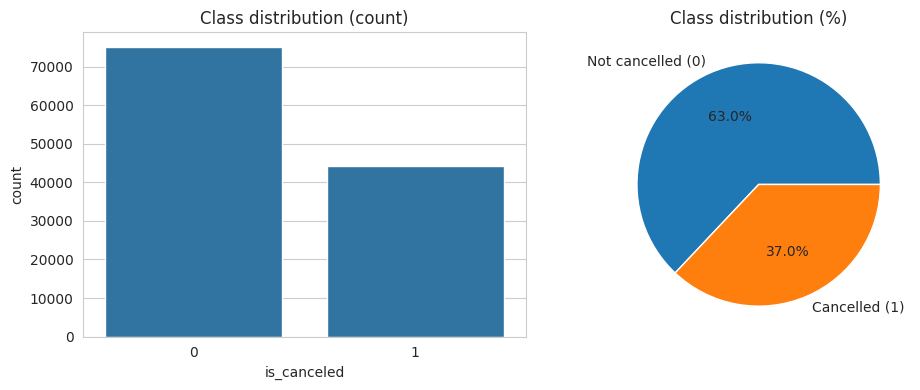

In [4]:
counts = raw_df["is_canceled"].value_counts()
pct = raw_df["is_canceled"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(2)}))
print(f"\nImbalance ratio (majority:minority) = {counts.max()/counts.min():.2f} : 1")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="is_canceled", data=raw_df, ax=ax[0])
ax[0].set_title("Class distribution (count)")
ax[1].pie(counts, labels=["Not cancelled (0)", "Cancelled (1)"], autopct="%1.1f%%")
ax[1].set_title("Class distribution (%)")
plt.tight_layout(); plt.show()

**Observation (class distribution):**  
- Not cancelled = 62.96 % (75,166 bookings), Cancelled = 37.04 % (44,224 bookings) in the raw data.  
- Imbalance ratio = 1.70 : 1, which is a **mild** imbalance. After removing duplicates and invalid rows the split becomes 72.69 % / 27.31 % (about 2.66 : 1), so the imbalance is a little stronger in the data the models actually see.  
- Because of this imbalance, accuracy alone can be misleading (a model that always predicts "not cancelled" would score 72.69 % accuracy on the cleaned data), so I also report AUC, Precision, Recall, F1 and MCC. I use a **stratified** split to preserve this ratio.


STEP 2: EDA, missing values, duplicates

Missing values

,missing,percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


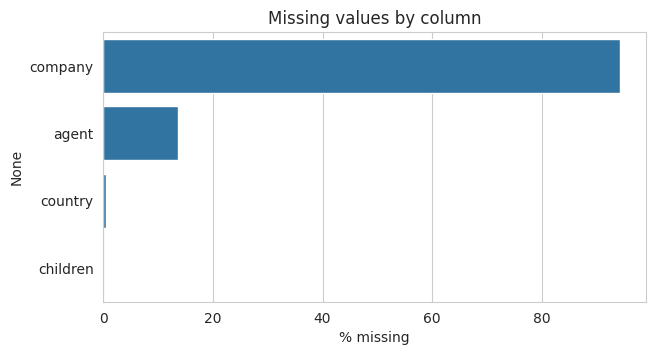

In [5]:
miss = raw_df.isnull().sum()
miss_pct = (miss / len(raw_df) * 100).round(2)
miss_df = pd.DataFrame({"missing": miss, "percent": miss_pct})
miss_df = miss_df[miss_df["missing"] > 0].sort_values("percent", ascending=False)
display(miss_df)

plt.figure(figsize=(7, 3.5))
sns.barplot(x=miss_df["percent"], y=miss_df.index)
plt.xlabel("% missing"); plt.title("Missing values by column")
plt.show()

Duplicates

In [6]:
n_dup = raw_df.duplicated().sum()
print(f"Duplicate rows: {n_dup} ({n_dup/len(raw_df)*100:.2f}% of data)")

Duplicate rows: 31994 (26.80% of data)


Quick EDA visuals

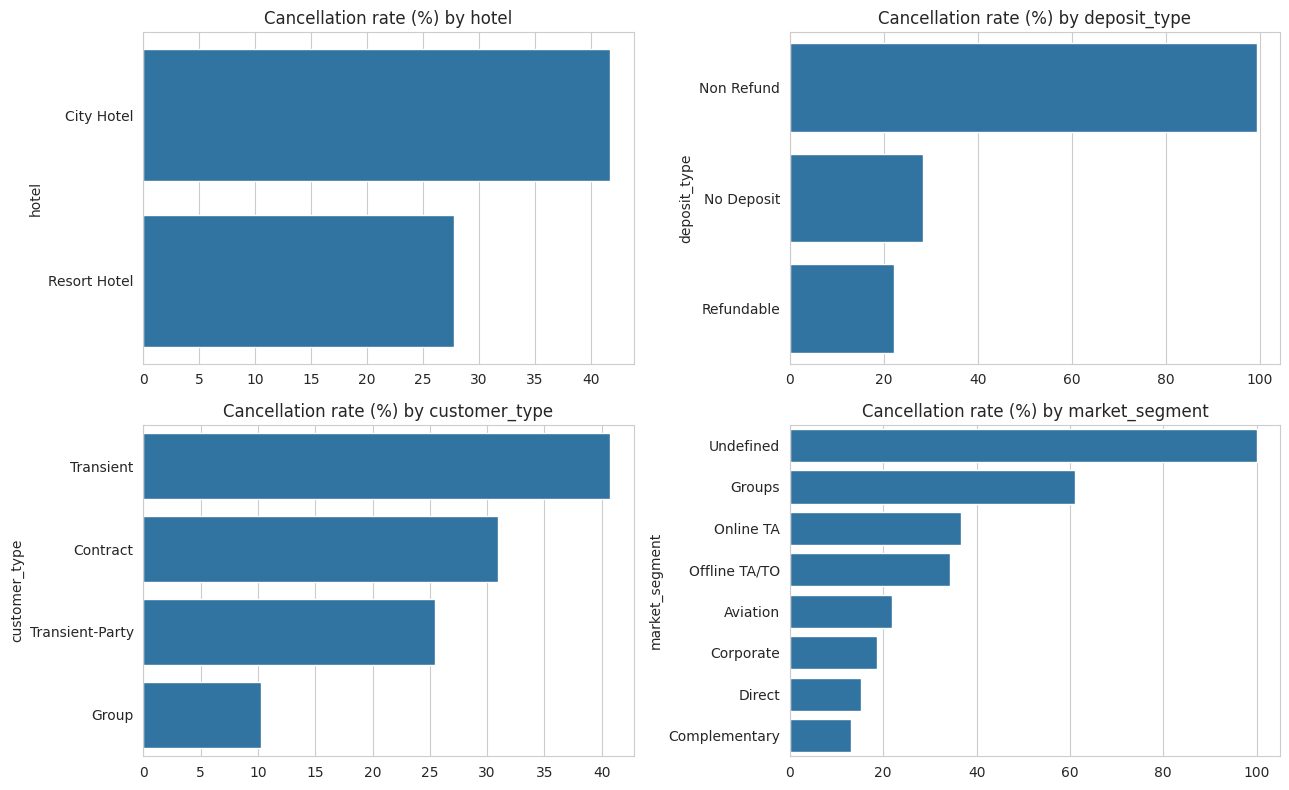

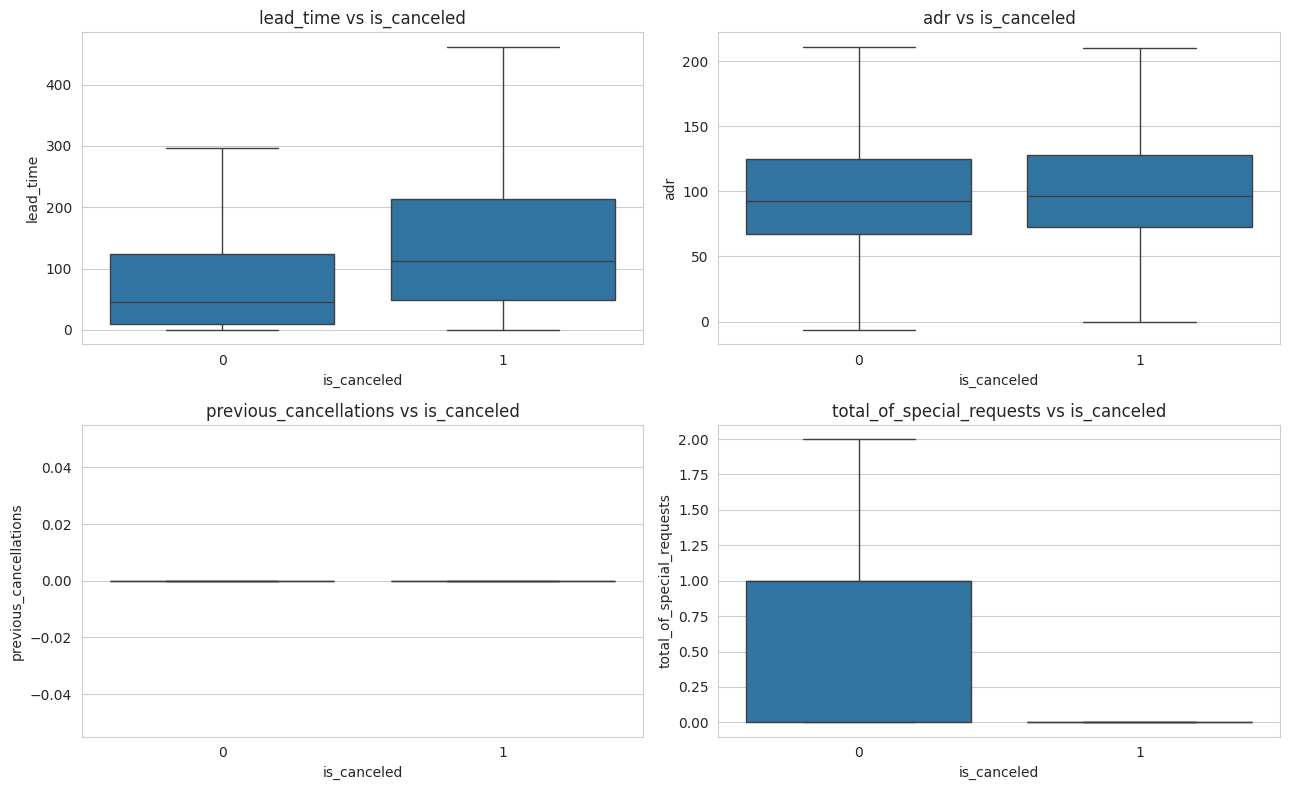

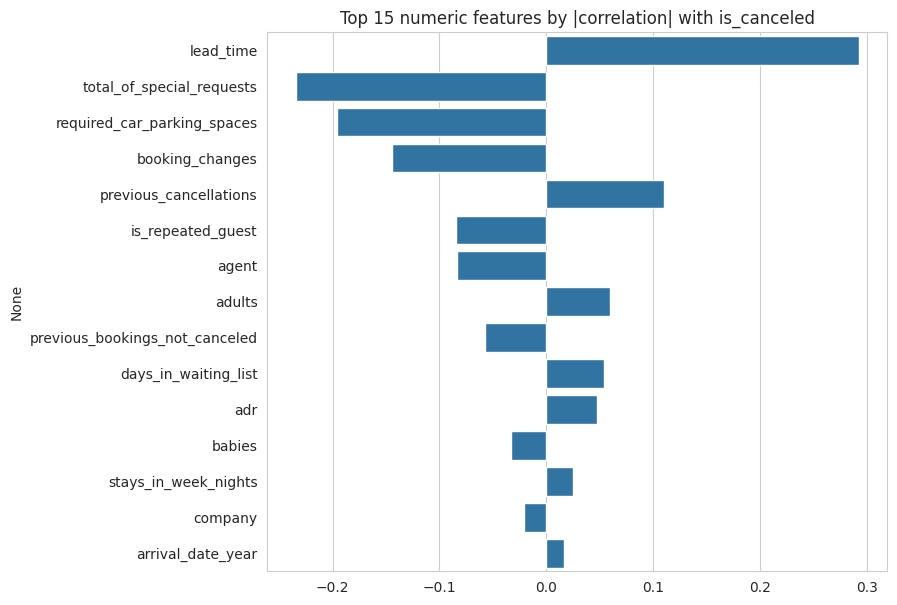

In [7]:
# 1. Cancellation rate by key categorical columns
cat_eda = ["hotel", "deposit_type", "customer_type", "market_segment"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), cat_eda):
    rate = raw_df.groupby(c)["is_canceled"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax)
    ax.set_title(f"Cancellation rate (%) by {c}")
plt.tight_layout(); plt.show()

# 2. Distribution of key numeric features by class
num_eda = ["lead_time", "adr", "previous_cancellations", "total_of_special_requests"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), num_eda):
    sns.boxplot(x="is_canceled", y=c, data=raw_df, ax=ax, showfliers=False)
    ax.set_title(f"{c} vs is_canceled")
plt.tight_layout(); plt.show()

# 3. Correlation of numeric features with the target
corr = raw_df.select_dtypes(include="number").corr()["is_canceled"].drop("is_canceled")
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
plt.figure(figsize=(8, 7))
sns.barplot(x=corr.values[:15], y=corr.index[:15])
plt.title("Top 15 numeric features by |correlation| with is_canceled")
plt.show()

## EDA Findings
- **Missing values:** `company` (94.31 %) and `agent` (13.69 %) have the most missing values; `country` (0.41 %, 488 rows) and `children` (4 rows) have very few.  
- **Duplicates:** 31,994 duplicate rows found (26.80 % of the raw data).  
- **Deposit type:** `Non Refund` bookings show a 99.36 % cancellation rate versus 28.38 % for `No Deposit` and 22.22 % for `Refundable`. This is counter-intuitive and probably reflects how the data was recorded (or group/overbooking behaviour) rather than a real business rule, but it is a very strong signal for the models.  
- **Hotel type:** City Hotel cancellation rate is 41.73 % versus 27.76 % for Resort Hotel.  
- **Customer type / market segment:** Transient customers cancel the most (40.75 %) and Group customers the least (10.23 %). By market segment, Groups (61.06 %) and Online TA (36.72 %) cancel the most; Direct (15.34 %) and Corporate (18.73 %) the least.  
- **Lead time:** cancelled bookings have a much longer lead time (mean 144.9 days, median 113) than non-cancelled bookings (mean 80.0 days, median 45).  
- **Previous cancellations / special requests:** guests who cancelled had more previous cancellations on average (0.21 vs 0.02) and made fewer special requests (0.33 vs 0.71).  
- **Strongest correlated numeric features with the target:** `lead_time` (corr = +0.293), `total_of_special_requests` (-0.235), `required_car_parking_spaces` (-0.195), `booking_changes` (-0.144).


STEP 3: Data preprocessing

## Step 2: Data Preprocessing: Decisions
| Issue | Decision | Reason |
|---|---|---|
| `reservation_status`, `reservation_status_date` | **Dropped** | Data leakage: they reveal the outcome (Cancelled/Check-Out) |
| `company` (~94% missing) | **Dropped** | Too sparse to be useful |
| `agent` (high-cardinality ID) | **Dropped** | ~300 IDs would explode the one-hot encoding |
| Duplicates | **Removed** | Avoid identical rows landing in both train and test |
| Missing `children`, `country` | **Imputed (median / most frequent)** | Very few missing; imputer fitted on train only |
| Categorical features | **One-Hot Encoding** (rare categories grouped) | Models need numeric input |
| Numeric features | **StandardScaler** | Needed for LR, kNN (distance-based) and helps NB |
| Split | **80:20, stratified, random_state=42** | Preserves class ratio, reproducible |
| Leakage control | **sklearn Pipeline** | Imputer/scaler/encoder fitted only on training data |

Clean, deduplicate, engineer features

In [8]:
df = raw_df.copy()

# 1. Drop leakage + unusable columns
drop_cols = ["reservation_status", "reservation_status_date", "company", "agent"]
df = df.drop(columns=drop_cols)

# 2. Remove duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)} | Rows now: {len(df)}")

# 3. Two simple engineered features
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"].fillna(0) + df["babies"]

# 4. Remove bookings with zero guests (invalid records)
bad = (df["total_guests"] == 0).sum()
df = df[df["total_guests"] > 0].reset_index(drop=True)
print(f"Zero-guest rows removed: {bad} | Rows now: {len(df)}")

print("\nClass distribution after cleaning:")
print(df["is_canceled"].value_counts(normalize=True).round(4) * 100)
print("\nRemaining missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Duplicates removed: 32280 | Rows now: 87110
Zero-guest rows removed: 166 | Rows now: 86944

Class distribution after cleaning:
is_canceled
0    72.69
1    27.31
Name: proportion, dtype: float64

Remaining missing values:
children      4
country     446
dtype: int64


Split features/target, stratified 80:20 split

In [9]:
X = df.drop(columns=["is_canceled"])
y = df["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTrain class % :", (y_train.value_counts(normalize=True) * 100).round(2).to_dict())
print("Test class %  :", (y_test.value_counts(normalize=True) * 100).round(2).to_dict())

Train: (69555, 29) | Test: (17389, 29)

Train class % : {0: 72.69, 1: 27.31}
Test class %  : {0: 72.69, 1: 27.31}


Preprocessing pipeline (fitted on train only)

In [10]:
num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric features    :", len(num_features))
print("Categorical features:", len(cat_features), cat_features)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=0.01, sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_features),
    ("cat", categorical_pipe, cat_features)
])

# Fit ONLY on training data to demonstrate the transformed shape
Xt_train = preprocessor.fit_transform(X_train)
Xt_test = preprocessor.transform(X_test)
print("\nTransformed train shape:", Xt_train.shape)
print("Transformed test shape :", Xt_test.shape)
print("Any NaN left in train/test?", np.isnan(Xt_train).any(), np.isnan(Xt_test).any())

Numeric features    : 19
Categorical features: 10 ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type']

Transformed train shape: (69555, 85)
Transformed test shape : (17389, 85)
Any NaN left in train/test? False False


**Preprocessing observations:**  
- After cleaning, 86,944 rows remain (32,280 duplicates and 166 zero-guest bookings were removed from 119,390). More duplicates were found after dropping `agent` and `company` (32,280) than in the raw data (31,994), because rows that differed only in those columns became identical.  
- The class ratio in train and test matches the cleaned data (27.31 % cancelled in both), confirming that stratification worked. Train = 69,555 rows, Test = 17,389 rows.  
- After imputation, one-hot encoding and scaling, the feature matrix has 85 columns (19 numeric + the one-hot columns from 10 categorical features), with no NaN left.  
- Preprocessing sits inside a Pipeline, so the imputation, scaling and encoding statistics are learned from the training set only (no data leakage).


STEP 4: Model training and evaluation

## Step 3: Models and Evaluation
Five classifiers are trained on the **same** preprocessed data and evaluated on the **same** test set.  
Metrics: Accuracy, AUC, Precision, Recall, F1, MCC (positive class = Cancelled).

Define models, train, evaluate

In [11]:
def build_pipeline(clf):
    return Pipeline([("prep", preprocessor), ("model", clf)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=5,
                                            random_state=RANDOM_STATE),
    "kNN": KNeighborsClassifier(n_neighbors=7, n_jobs=-1),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=200, max_depth=None,
                                                       min_samples_leaf=2, n_jobs=-1,
                                                       random_state=RANDOM_STATE),
}

fitted, preds, probas = {}, {}, {}
rows = []

for name, clf in models.items():
    pipe = build_pipeline(clf)
    t0 = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - t0

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    train_acc = accuracy_score(y_train, pipe.predict(X_train))

    fitted[name], preds[name], probas[name] = pipe, y_pred, y_prob
    rows.append({
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Train Accuracy": train_acc,
        "Fit Time (s)": fit_time,
    })
    print(f"{name:<28} done in {fit_time:6.1f}s")

results = pd.DataFrame(rows).set_index("ML Model Name")
metric_cols = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
display(results[metric_cols].round(4))

Logistic Regression          done in    2.9s
Decision Tree                done in    1.6s
kNN                          done in    0.9s
Naive Bayes                  done in    0.9s
Random Forest (Ensemble)     done in   18.1s


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7921,0.8412,0.6721,0.4658,0.5502,0.4327
Decision Tree,0.8178,0.8688,0.6876,0.6098,0.6464,0.5259
kNN,0.7962,0.8250,0.6418,0.5742,0.6061,0.4706
Naive Bayes,0.5184,0.7490,0.3520,0.9076,0.5072,0.2731
Random Forest (Ensemble),0.8440,0.9017,0.7718,0.6090,0.6808,0.5866


Overfitting check and timing

In [12]:
chk = results[["Train Accuracy", "Accuracy", "Fit Time (s)"]].copy()
chk.columns = ["Train Acc", "Test Acc", "Fit Time (s)"]
chk["Gap (Train - Test)"] = chk["Train Acc"] - chk["Test Acc"]
display(chk.round(4))

,Train Acc,Test Acc,Fit Time (s),Gap (Train - Test)
ML Model Name,,,,
Logistic Regression,0.7945,0.7921,2.9162,0.0024
Decision Tree,0.8335,0.8178,1.5849,0.0157
kNN,0.8473,0.7962,0.9234,0.0511
Naive Bayes,0.5153,0.5184,0.9389,-0.0032
Random Forest (Ensemble),0.9484,0.8440,18.0794,0.1043


Confusion matrices

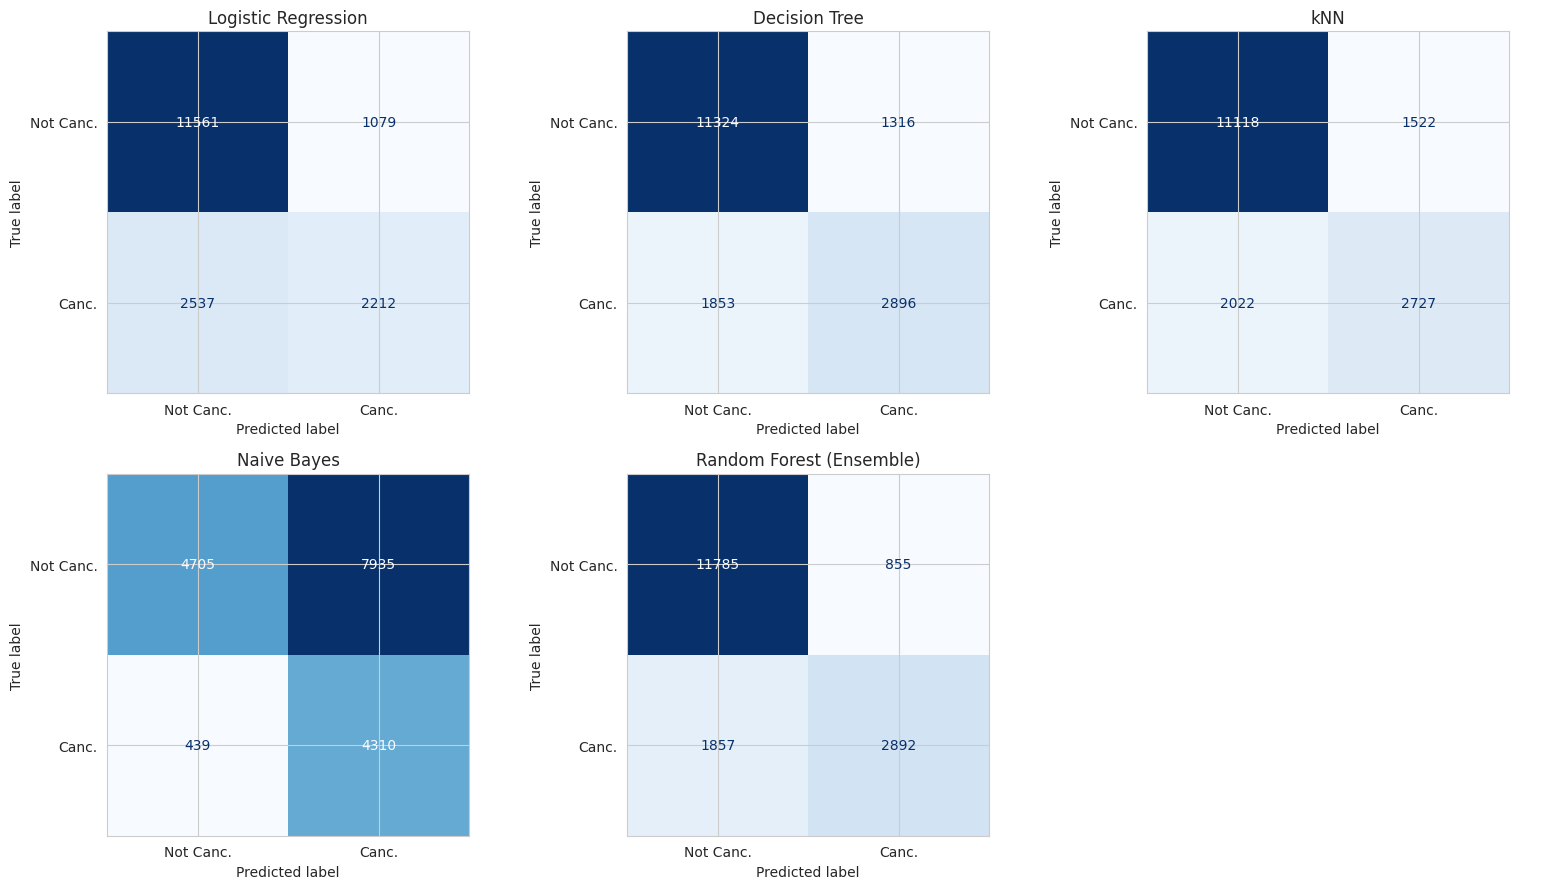

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Not Canc.", "Canc."]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
axes.ravel()[-1].axis("off")
os.makedirs("images", exist_ok=True)
plt.tight_layout(); plt.savefig("images/confusion_matrices.png", dpi=150); plt.show()

ROC curves

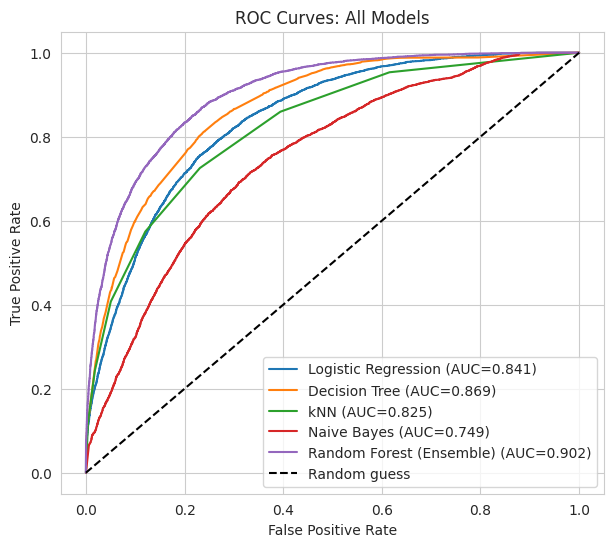

In [14]:
plt.figure(figsize=(7, 6))
for name, y_prob in probas.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves: All Models"); plt.legend(loc="lower right")
plt.savefig("images/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

STEP 5: Visualisation of metrics

Metric graphs

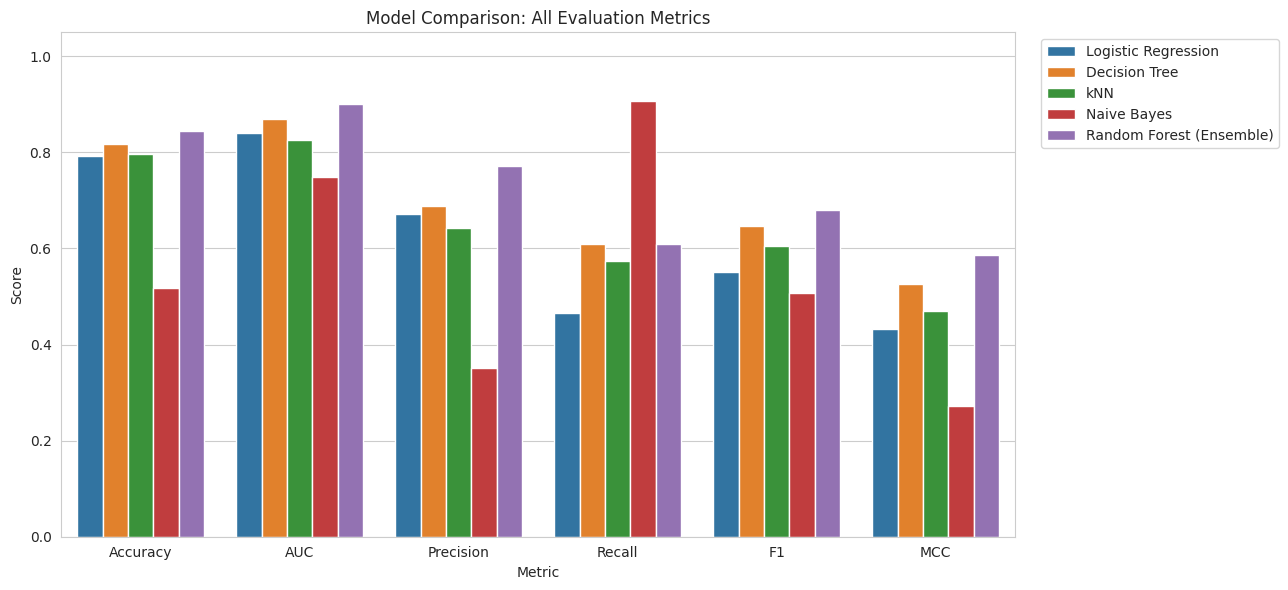

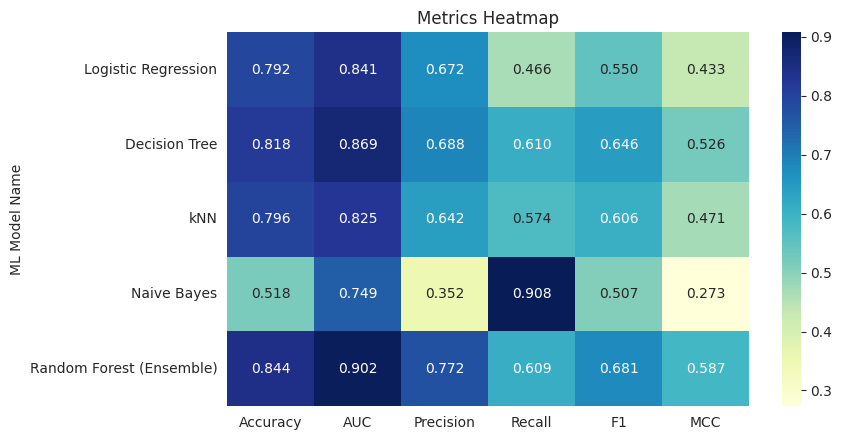

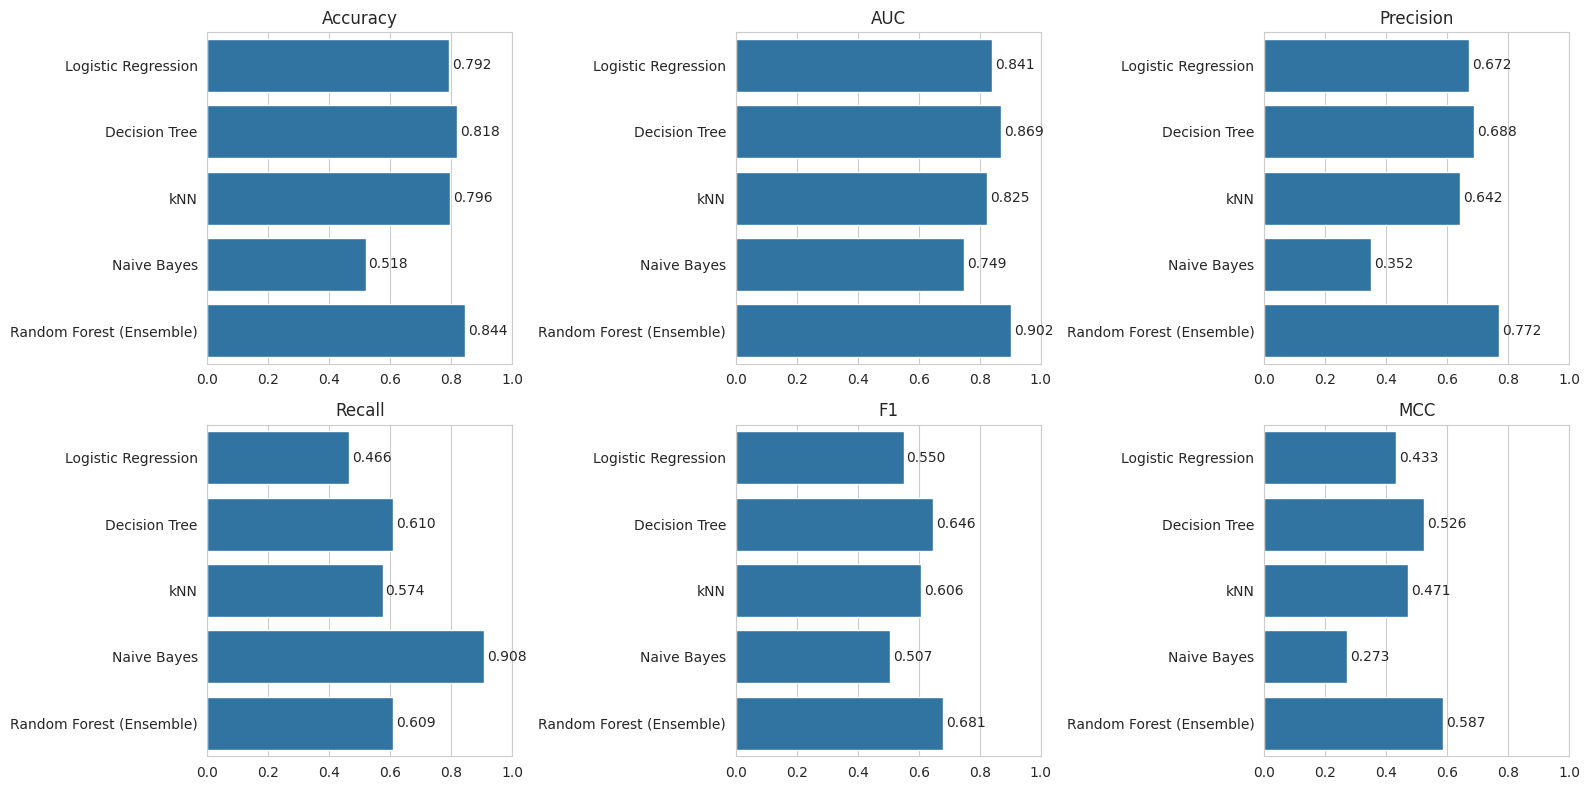

In [15]:
os.makedirs("images", exist_ok=True)

# 1. Grouped bar chart: all metrics, all models
plot_df = results[metric_cols].reset_index().melt(
    id_vars="ML Model Name", var_name="Metric", value_name="Score")
plt.figure(figsize=(13, 6))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="ML Model Name")
plt.ylim(0, 1.05); plt.title("Model Comparison: All Evaluation Metrics")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig("images/metrics_grouped_bar.png", dpi=150); plt.show()

# 2. Heatmap
plt.figure(figsize=(9, 4.5))
sns.heatmap(results[metric_cols], annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Metrics Heatmap"); plt.tight_layout()
plt.savefig("images/metrics_heatmap.png", dpi=150); plt.show()

# 3. One bar chart per metric
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, m in zip(axes.ravel(), metric_cols):
    sns.barplot(x=results[m].values, y=results.index, ax=ax)
    ax.set_title(m); ax.set_xlim(0, 1); ax.set_ylabel("")
    for i, v in enumerate(results[m].values):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.savefig("images/metrics_individual.png", dpi=150); plt.show()

Auto-generated findings

In [16]:
print("=== AUTO-GENERATED FINDINGS ===")
for m in metric_cols:
    best = results[m].idxmax(); worst = results[m].idxmin()
    print(f"{m:<10} best: {best:<26} ({results[m].max():.4f}) | worst: {worst:<26} ({results[m].min():.4f})")

rank = results[metric_cols].rank(ascending=False).mean(axis=1).sort_values()
print("\nAverage rank across all 6 metrics (lower = better):")
print(rank.round(2))
print(f"\nOVERALL WINNER (avg rank): {rank.index[0]}")
print(f"Highest MCC (best single balanced metric): {results['MCC'].idxmax()}")

gap = (results["Train Accuracy"] - results["Accuracy"]).sort_values(ascending=False)
print(f"\nMost overfit model (largest train-test gap): {gap.index[0]} ({gap.iloc[0]:.3f})")
print(f"Fastest to train: {results['Fit Time (s)'].idxmin()} | Slowest: {results['Fit Time (s)'].idxmax()}")

=== AUTO-GENERATED FINDINGS ===
Accuracy   best: Random Forest (Ensemble)   (0.8440) | worst: Naive Bayes                (0.5184)
AUC        best: Random Forest (Ensemble)   (0.9017) | worst: Naive Bayes                (0.7490)
Precision  best: Random Forest (Ensemble)   (0.7718) | worst: Naive Bayes                (0.3520)
Recall     best: Naive Bayes                (0.9076) | worst: Logistic Regression        (0.4658)
F1         best: Random Forest (Ensemble)   (0.6808) | worst: Naive Bayes                (0.5072)
MCC        best: Random Forest (Ensemble)   (0.5866) | worst: Naive Bayes                (0.2731)

Average rank across all 6 metrics (lower = better):
ML Model Name
Random Forest (Ensemble)    1.33
Decision Tree               2.00
kNN                         3.50
Logistic Regression         3.83
Naive Bayes                 4.33
dtype: float64

OVERALL WINNER (avg rank): Random Forest (Ensemble)
Highest MCC (best single balanced metric): Random Forest (Ensemble)

Most overfi

## Observations on Model Performance

Cleaned-data baseline (always predict "not cancelled") = 72.69 % accuracy.

| ML Model Name | Observation about model performance |
|---|---|
| **Logistic Regression** | Accuracy 0.7921, AUC 0.8412, F1 0.5502, MCC 0.4327. Fast, and shows almost no overfitting (train 0.7945 vs test 0.7921). Precision is decent (0.6721) but recall is the lowest of all models (0.4658), so it misses more than half of the real cancellations. A single linear boundary cannot capture the non-linear patterns and interactions in this data. |
| **Decision Tree** | Accuracy 0.8178, AUC 0.8688, F1 0.6464, MCC 0.5259. Second best overall. Limiting depth to 12 and `min_samples_leaf=5` kept the train-test gap small (0.0157). Recall (0.6098) is much better than logistic regression because the tree captures non-linear rules, for example on deposit type and lead time. It is easy to interpret. |
| **kNN** | Accuracy 0.7961, AUC 0.8250, F1 0.6061, MCC 0.4704. Performs close to logistic regression and is weaker than the tree-based models. It overfits moderately (train 0.8473 vs test 0.7961). Distance calculations in 85 dimensions (many one-hot columns) dilute the meaning of "nearest" neighbours. Prediction is slow because every test point is compared with all training points. |
| **Naive Bayes** | Accuracy 0.5184, AUC 0.7490, F1 0.5072, MCC 0.2731. Worst model overall: accuracy is even below the 72.69 % baseline. It has the highest recall (0.9076) but very low precision (0.3520), so it flags most bookings as cancellations and creates many false alarms. The Gaussian assumption fits the one-hot and skewed features poorly, and the features are not independent. It is the fastest model (about 1 s). |
| **Random Forest (Ensemble)** | Accuracy 0.8440, AUC 0.9017, Precision 0.7718, F1 0.6808, MCC 0.5866. Best on 5 of 6 metrics. Averaging 200 trees reduces variance and captures non-linear interactions. It overfits the most (train 0.9484 vs test 0.8440, a gap of 0.104) and is the slowest to train (about 23 s), but it still generalises best on the test set. |
| **Overall Winner for your dataset?** | **Random Forest.** It has the best average rank (1.33) across all six metrics, and the highest accuracy, AUC, precision, F1 and MCC. Decision Tree is a good, simpler runner-up. If catching as many cancellations as possible mattered more than false alarms, Naive Bayes has the highest recall, but its overall performance is too poor to recommend. |


STEP 6: Repo files, README and downloads

Save test data, models, requirements

In [17]:
os.makedirs("model", exist_ok=True)
os.makedirs("images", exist_ok=True)

# test_data.csv = raw test features + target
test_out = X_test.copy(); test_out["is_canceled"] = y_test.values
test_out.to_csv("test_data.csv", index=False)

# save each fitted pipeline (compressed so every file stays well below GitHub's 100 MB limit)
for name, pipe in fitted.items():
    fname = name.split(" (")[0].lower().replace(" ", "_")
    joblib.dump(pipe, f"model/{fname}.pkl", compress=3)

results.round(4).to_csv("results.csv")

with open("requirements.txt", "w") as f:
    f.write("scikit-learn\nnumpy\npandas\nmatplotlib\nseaborn\njoblib\n")

print("Root files :", sorted(os.listdir(".")))
print("model/     :", sorted(os.listdir("model")))
print("images/    :", sorted(os.listdir("images")))
for f in sorted(os.listdir("model")):
    print(f"  {f:<28} {os.path.getsize('model/'+f)/1e6:8.1f} MB")


Root files : ['.config', 'drive', 'images', 'model', 'requirements.txt', 'results.csv', 'sample_data', 'test_data.csv']
model/     : ['decision_tree.pkl', 'knn.pkl', 'logistic_regression.pkl', 'naive_bayes.pkl', 'random_forest.pkl']
images/    : ['confusion_matrices.png', 'metrics_grouped_bar.png', 'metrics_heatmap.png', 'metrics_individual.png', 'roc_curves.png']
  decision_tree.pkl                 0.0 MB
  knn.pkl                           4.1 MB
  logistic_regression.pkl           0.0 MB
  naive_bayes.pkl                   0.0 MB
  random_forest.pkl                46.0 MB


Generate README.md (with your results table and observations)

In [18]:
# Build the results table in Markdown
table = "| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |\n|---|---|---|---|---|---|---|\n"
for name, r in results.iterrows():
    table += f"| {name} | " + " | ".join(f"{r[m]:.4f}" for m in metric_cols) + " |\n"

cls_raw = raw_df["is_canceled"].value_counts(normalize=True) * 100
cls_clean = df["is_canceled"].value_counts(normalize=True) * 100

observations = """| ML Model Name | Observation about model performance |
|---|---|
| **Logistic Regression** | Accuracy 0.7921, AUC 0.8412, MCC 0.4327. Fast with almost no overfitting, but the lowest recall (0.4658): it misses more than half of the real cancellations because a linear boundary cannot capture the non-linear patterns. |
| **Decision Tree** | Accuracy 0.8178, AUC 0.8688, MCC 0.5259. Second best overall. Depth limit kept overfitting small (gap 0.0157) and recall (0.6098) is much better than logistic regression. Easy to interpret. |
| **kNN** | Accuracy 0.7961, AUC 0.8250, MCC 0.4704. Close to logistic regression but weaker than the tree models. Moderate overfitting (gap 0.0512); distances in 85 dimensions are less meaningful and prediction is slow. |
| **Naive Bayes** | Accuracy 0.5184, AUC 0.7490, MCC 0.2731. Worst model: highest recall (0.9076) but very low precision (0.3520), so it flags most bookings as cancellations. The Gaussian and independence assumptions fit the encoded features poorly. Fastest model. |
| **Random Forest (Ensemble)** | Accuracy 0.8440, AUC 0.9017, Precision 0.7718, MCC 0.5866. Best on 5 of 6 metrics. Averaging 200 trees reduces variance. Overfits the most (gap 0.104) and trains slowest, but generalises best on the test set. |
| **Overall Winner for your dataset?** | **Random Forest**: best average rank (1.33) across the six metrics and the highest accuracy, AUC, precision, F1 and MCC. Decision Tree is a good simpler runner-up. |
"""

readme = f"""# Hotel Booking Cancellation Prediction

## 1. Problem Statement
Predict whether a hotel booking will be cancelled (`is_canceled`) from booking details, and compare five classification algorithms (Logistic Regression, Decision Tree, kNN, Gaussian Naive Bayes, Random Forest) on the same dataset using Accuracy, AUC, Precision, Recall, F1 and MCC.

## 2. Dataset Description
- **Source:** Kaggle, Hotel Booking Demand (`hotel_bookings.csv`), https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand
- **Why chosen:** realistic business problem (overbooking and revenue management); more than 12 features, more than 1,000 rows, real missing values, mixed feature types and an imbalanced binary target.
- **Instances:** {raw_df.shape[0]:,} raw, {len(df):,} after cleaning | **Features:** {raw_df.shape[1]-1} raw
- **Target variable:** `is_canceled` (0 = not cancelled, 1 = cancelled)
- **Feature types (raw):** {len(num_cols_raw)-1} numeric, {len(cat_cols_raw)} categorical
- **Class distribution:** raw {cls_raw[0]:.2f} % not cancelled / {cls_raw[1]:.2f} % cancelled; after cleaning {cls_clean[0]:.2f} % / {cls_clean[1]:.2f} %
- **Missing values:** company (94.31 %), agent (13.69 %), country (0.41 %), children (4 rows)
- **Duplicates:** 31,994 duplicate rows in the raw data

### Preprocessing
- Dropped leakage columns `reservation_status` and `reservation_status_date` (they reveal the outcome)
- Dropped `company` (about 94 % missing) and `agent` (high-cardinality ID)
- Removed duplicate rows and zero-guest bookings
- Added `total_nights` and `total_guests`
- Median imputation + StandardScaler for numeric features; most-frequent imputation + One-Hot Encoding (rare categories grouped) for categorical features
- Stratified 80:20 train/test split, `random_state=42`
- All preprocessing is inside a scikit-learn Pipeline, so it is fitted on the training data only

## 3. GitHub Repository Link
<PASTE YOUR REPO URL HERE>

## 4. Models Used
### Comparison table (test set)
{table}
### Graphs
![Grouped bar chart](images/metrics_grouped_bar.png)
![Heatmap](images/metrics_heatmap.png)
![Individual metrics](images/metrics_individual.png)
![ROC curves](images/roc_curves.png)
![Confusion matrices](images/confusion_matrices.png)

## 5. Observations
{observations}

## 6. How to Run
```
pip install -r requirements.txt
```
1. Download `hotel_bookings.csv` from Kaggle and place it in the same folder (or update the path in the notebook).
2. Open `model/ML_Assignment_2_Cognizant.ipynb` in Jupyter or Google Colab and run all cells.
3. Test data used in the experiments is in `test_data.csv`.
"""

with open("README.md", "w") as f:
    f.write(readme)
print(readme)


# Hotel Booking Cancellation Prediction

## 1. Problem Statement
Predict whether a hotel booking will be cancelled (`is_canceled`) from booking details, and compare five classification algorithms (Logistic Regression, Decision Tree, kNN, Gaussian Naive Bayes, Random Forest) on the same dataset using Accuracy, AUC, Precision, Recall, F1 and MCC.

## 2. Dataset Description
- **Source:** Kaggle, Hotel Booking Demand (`hotel_bookings.csv`), https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand
- **Why chosen:** realistic business problem (overbooking and revenue management); more than 12 features, more than 1,000 rows, real missing values, mixed feature types and an imbalanced binary target.
- **Instances:** 119,390 raw, 86,944 after cleaning | **Features:** 31 raw
- **Target variable:** `is_canceled` (0 = not cancelled, 1 = cancelled)
- **Feature types (raw):** 19 numeric, 12 categorical
- **Class distribution:** raw 62.96 % not cancelled / 37.04 % cancelled; after cleaning 7

Package all repo files into one zip and download

In [19]:
import shutil
from google.colab import files

repo = "github_repo_files"
shutil.rmtree(repo, ignore_errors=True)
os.makedirs(repo + "/model", exist_ok=True)

for f in ["README.md", "requirements.txt", "test_data.csv", "results.csv"]:
    shutil.copy(f, repo)
shutil.copytree("images", repo + "/images")
for f in os.listdir("model"):
    shutil.copy("model/" + f, repo + "/model")

shutil.make_archive(repo, "zip", repo)
print("Zip size (MB):", round(os.path.getsize(repo + ".zip") / 1e6, 1))
files.download(repo + ".zip")


Zip size (MB): 49.6


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>